# J4F Commerce Intelligence — Improvement Pattern Discovery

**Mục tiêu:** Khám phá các **tổ hợp đề xuất rà soát listing** xuất hiện cùng nhau; kiểm tra chúng khác nhau thế nào theo `product_type` và trạng thái. Đây là nghiên cứu *mẫu hình đầu ra của hệ thống*, **không** đánh giá lại pipeline của NL, và cũng **không** chứng minh tác động nhân quả đến doanh số.

**Câu hỏi nghiên cứu**
1. RQ1 — Các tổ hợp `rule_id` phổ biến nhất là gì?
2. RQ2 — Mẫu hình nào có mức độ phổ biến đặc trưng theo `product_type`?
3. RQ3 — Mẫu hình có phân bố khác nhau theo `status` không?
4. RQ4 — Mỗi sản phẩm cần rà soát bao nhiêu hạng mục? Có nhóm hành động đơn/kết hợp đáng để thiết kế UX không?

**Đầu ra:** bảng CSV, biểu đồ PNG, tóm tắt Markdown và danh sách sản phẩm minh họa. Các nhãn pattern được xây dựng từ tổ hợp rule thực tế, không gán sẵn kết luận.

In [1]:
from pathlib import Path
import re, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Tự nhận diện thư mục repo khi mở notebook từ VS Code hoặc chạy từ terminal.
def find_root():
    for start in [Path.cwd(), Path.home() / "Documents" / "j4f-commerce-intelligence"]:
        for p in [start, *start.parents]:
            if (p / 'data' / 'processed').exists() and (p / 'ml').exists():
                return p
    raise FileNotFoundError('Không tìm thấy repo. Hãy mở VS Code tại thư mục j4f-commerce-intelligence.')
ROOT = find_root()
BASE = ROOT / 'data' / 'processed' / 'scoring_mvp_v2'
OUTPUT = ROOT / 'data' / 'processed' / 'improvement_pattern_outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)
STATUS_FILE = BASE / 'product_statuses.csv'
REC_FILE = BASE / 'product_recommendations.csv'
for f in [STATUS_FILE, REC_FILE]:
    if not f.exists(): raise FileNotFoundError(f'Thiếu {f}. Hãy giải nén ZIP NL vào data/processed/scoring_mvp_v2/')
print('Repo:', ROOT)
print('Output:', OUTPUT)

Repo: /Users/nhung/Documents/j4f-commerce-intelligence
Output: /Users/nhung/Documents/j4f-commerce-intelligence/data/processed/improvement_pattern_outputs


## 0. Data contract và các kiểm tra đầu vào

Giữ mỗi `product_id` một lần ở bảng status; ở recommendation, một `product_id` có thể có nhiều dòng rule. Không tính **số dòng đề xuất** như **số sản phẩm**.

In [2]:
statuses = pd.read_csv(STATUS_FILE, low_memory=False)
recs = pd.read_csv(REC_FILE, low_memory=False)
need_s = {'product_id','product_name','product_type','status'}
need_r = {'product_id','rule_id'}
assert need_s.issubset(statuses.columns), f'Thiếu cột status: {need_s - set(statuses.columns)}'
assert need_r.issubset(recs.columns), f'Thiếu cột recommendations: {need_r - set(recs.columns)}'
assert not statuses.product_id.duplicated().any(), 'Status có product_id trùng; cần kiểm tra lại lần chạy'
assert not recs[['product_id','rule_id']].duplicated().any(), 'Có duplicate product_id + rule_id; cần làm rõ'
unknown = set(recs.product_id) - set(statuses.product_id)
assert not unknown, f'{len(unknown)} product_id trong recommendation không có status'
print('Sản phẩm:',len(statuses), '| Đề xuất:',len(recs), '| SP có đề xuất:',recs.product_id.nunique())
print('Rule hiện có:', sorted(recs.rule_id.unique().tolist()))
print('Trạng thái:', statuses.status.value_counts().to_dict())

Sản phẩm: 41576 | Đề xuất: 42652 | SP có đề xuất: 27696
Rule hiện có: ['add_product_images', 'consider_product_video', 'improve_product_description', 'review_price_positioning', 'review_quality_feedback', 'review_visibility_and_stock']
Trạng thái: {'performing_well': 18176, 'difficult_to_sell': 12380, 'untapped_potential': 5892, 'insufficient_data': 5128}


## 1. Chuẩn bị tổ hợp rule ở cấp sản phẩm

`pattern_exact` là tập hợp `rule_id` được sắp xếp theo alphabet; `No recommendation` được giữ riêng thay vì loại bỏ. Khi kết luận về **loại đề xuất**, ưu tiên `rule_id` thật, tránh nhầm lẫn từ tên nhãn diễn giải.

In [3]:
patterns = (recs.groupby('product_id')['rule_id']
            .agg(lambda s: tuple(sorted(set(s.astype(str)))))
            .rename('rules_tuple'))
products = statuses.merge(patterns, how='left', left_on='product_id', right_index=True, validate='one_to_one')
products['rules_tuple'] = products.rules_tuple.apply(lambda x: x if isinstance(x,tuple) else tuple())
products['n_actions'] = products.rules_tuple.map(len)
products['pattern_exact'] = products.rules_tuple.map(lambda x: ' + '.join(x) if x else 'No recommendation')
products['has_recommendations'] = products.n_actions.gt(0)
print('Đối chiếu số dòng:', len(products), len(statuses))
display(products[['product_id','product_type','status','n_actions','pattern_exact']].head())

Đối chiếu số dòng: 41576 41576


,product_id,product_type,status,n_actions,pattern_exact
0,100002175,túi đeo chéo,performing_well,2,add_product_images + review_price_positioning
1,100084336,phụ kiện vệ sinh giày,performing_well,1,review_price_positioning
2,100087685,dép nữ,performing_well,1,add_product_images
3,100128769,sandal nam,performing_well,1,review_price_positioning
4,100142522,mũ nón,performing_well,2,add_product_images + review_price_positioning


## RQ1 — Những tổ hợp xuất hiện phổ biến nhất?

Đọc kết quả theo **số sản phẩm**, không phải số dòng recommendation. Có cả tỷ lệ trên toàn bộ sản phẩm và trên sản phẩm có ít nhất một đề xuất. Lưu ý các tổ hợp có thể phản ánh rule thiết kế, không nhất thiết là mối quan hệ tự nhiên giữa các đặc tính listing.

,pattern_exact,n_products,mean_actions,pct_all,pct_with_recs
0,No recommendation,13880,0.0,33.38,NaN
1,add_product_images,6416,1.0,15.43,23.17
37,review_price_positioning,5774,1.0,13.89,20.85
17,add_product_images + review_price_positioning,4092,2.0,9.84,14.77
41,review_visibility_and_stock,1733,1.0,4.17,6.26
21,add_product_images + review_visibility_and_stock,1389,2.0,3.34,5.02
39,review_price_positioning + review_visibility_a...,1025,2.0,2.47,3.70
22,consider_product_video,953,1.0,2.29,3.44
2,add_product_images + consider_product_video,827,2.0,1.99,2.99
19,add_product_images + review_price_positioning ...,821,3.0,1.97,2.96


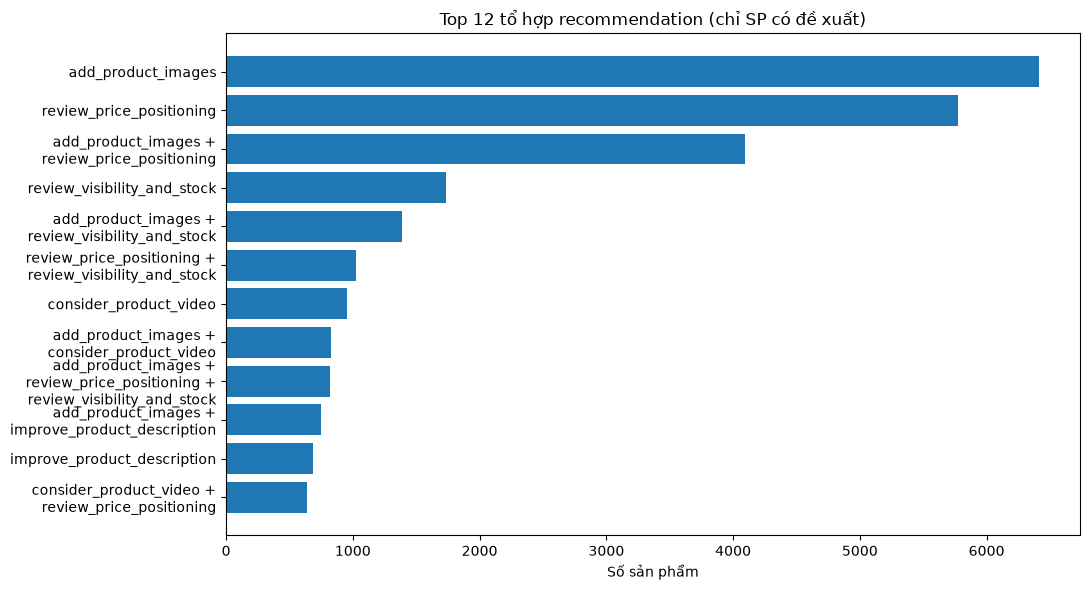

In [4]:
total = len(products); n_with = int(products.has_recommendations.sum())
frequency = (products.groupby('pattern_exact', dropna=False).agg(
    n_products=('product_id','size'), mean_actions=('n_actions','mean')).reset_index()
    .sort_values('n_products',ascending=False))
frequency['pct_all'] = (100*frequency.n_products/total).round(2)
frequency['pct_with_recs'] = np.where(frequency.pattern_exact.ne('No recommendation'),
                                       100*frequency.n_products/max(n_with,1),np.nan).round(2)
frequency.to_csv(OUTPUT/'rq1_exact_pattern_frequency.csv',index=False)
display(frequency.head(18))
fig,ax=plt.subplots(figsize=(11,6))
top=frequency[frequency.pattern_exact!='No recommendation'].head(12).iloc[::-1]
ax.barh([s.replace(' + ', ' +\n') for s in top.pattern_exact], top.n_products)
ax.set_xlabel('Số sản phẩm');ax.set_title('Top 12 tổ hợp recommendation (chỉ SP có đề xuất)')
fig.tight_layout();fig.savefig(OUTPUT/'rq1_top_patterns.png',dpi=160);plt.show()

### Những hạng mục nào thường đi chung?

Đếm đồng xuất hiện của **hai rule** và chỉ số `lift` mô tả mức độ đồng xuất hiện so với nếu độc lập về mặt tần suất. Không diễn giải lift thành tác động nhân quả, và không xem đây là đánh giá độ đúng của rule.

In [5]:
from itertools import combinations
rules=sorted(recs.rule_id.dropna().unique().tolist())
mat=pd.DataFrame({r: products.rules_tuple.map(lambda rr:r in rr).to_numpy(dtype=bool) for r in rules})
rows=[]
for a,bb in combinations(rules,2):
    both=int((mat[a]&mat[bb]).sum()); pa=mat[a].mean();pb=mat[bb].mean()
    rows.append(dict(rule_a=a,rule_b=bb,n_both=both,pct_all=round(100*both/total,2),
                     lift=round((both/total)/(pa*pb),3) if pa*pb else np.nan))
pairs=pd.DataFrame(rows).sort_values('n_both',ascending=False)
pairs.to_csv(OUTPUT/'rq1_rule_cooccurrence.csv',index=False)
display(pairs.head(15))

,rule_a,rule_b,n_both,pct_all,lift
2,add_product_images,review_price_positioning,6136,14.76,1.135
4,add_product_images,review_visibility_and_stock,2670,6.42,1.180
13,review_price_positioning,review_visibility_and_stock,2154,5.18,1.080
0,add_product_images,consider_product_video,1857,4.47,1.254
6,consider_product_video,review_price_positioning,1529,3.68,1.171
1,add_product_images,improve_product_description,1492,3.59,1.432
9,improve_product_description,review_price_positioning,898,2.16,0.977
8,consider_product_video,review_visibility_and_stock,632,1.52,1.156
11,improve_product_description,review_visibility_and_stock,328,0.79,0.853
5,consider_product_video,improve_product_description,245,0.59,0.973


## RQ2 — Mẫu hình có khác nhau theo product type không?

Để không bị đánh lừa bởi nhóm quá ít sản phẩm, mặc định chỉ trình bày `product_type` có **≥ 150 sản phẩm**. So sánh tỷ lệ tổ hợp *trong mỗi loại hàng*, đồng thời đối chiếu tỷ lệ chung và chênh lệch điểm phần trăm. Tỷ lệ này là mô tả, chưa khẳng định khác biệt có ý nghĩa thống kê.

,product_type,pattern_exact,count,type_n,pct_within_type,pct_global,diff_pp
96,cà vạt,improve_product_description,90,459,19.61,1.647585,17.96
765,sandal khác,improve_product_description,38,286,13.29,1.647585,11.64
275,giày lười nam,add_product_images,211,840,25.12,15.431980,9.69
313,giày nam,add_product_images,49,199,24.62,15.431980,9.19
325,giày thể thao khác,add_product_images,95,399,23.81,15.431980,8.38
487,hình xăm tạm thời,review_price_positioning,116,554,20.94,13.887820,7.05
914,túi laptop công sở,consider_product_video,125,1364,9.16,2.292188,6.87
971,túi xách khác,review_price_positioning,84,405,20.74,13.887820,6.85
1094,ví khác,consider_product_video,75,823,9.11,2.292188,6.82
815,sandal nữ,improve_product_description,67,800,8.38,1.647585,6.73


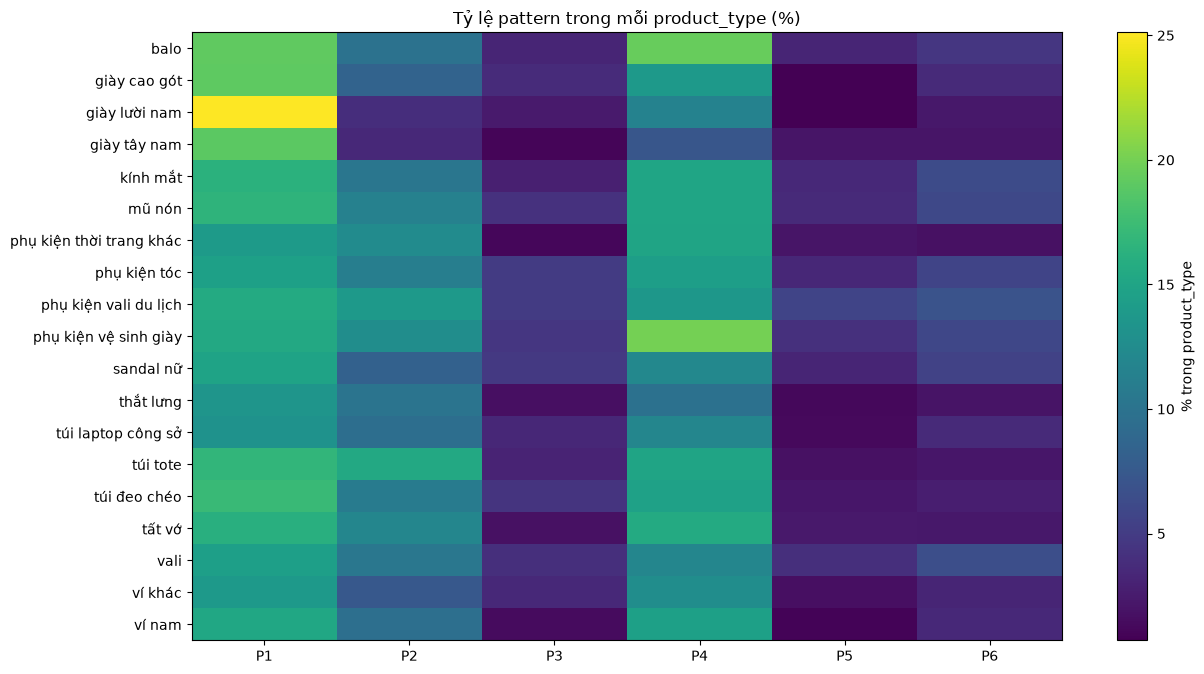

Chú giải: {'P1': 'add_product_images', 'P2': 'add_product_images + review_price_positioning', 'P3': 'add_product_images + review_visibility_and_stock', 'P4': 'review_price_positioning', 'P5': 'review_price_positioning + review_visibility_and_stock', 'P6': 'review_visibility_and_stock'}


In [6]:
MIN_TYPE_N=150
MIN_PATTERN_N=100
eligible_types=products.product_type.value_counts()
eligible_types=eligible_types[eligible_types>=MIN_TYPE_N].index
eligible_patterns=frequency[(frequency.n_products>=MIN_PATTERN_N)&(frequency.pattern_exact!='No recommendation')].pattern_exact.tolist()
sub=products[products.product_type.isin(eligible_types)].copy()
num=(sub.groupby(['product_type','pattern_exact']).size().rename('count').reset_index())
denom=sub.groupby('product_type').size().rename('type_n').reset_index()
type_pattern=num.merge(denom,on='product_type')
type_pattern['pct_within_type']=(100*type_pattern['count']/type_pattern['type_n']).round(2)
global_rate=products.pattern_exact.value_counts(normalize=True).mul(100).rename('pct_global')
type_pattern=type_pattern.merge(global_rate, left_on='pattern_exact',right_index=True)
type_pattern['diff_pp']=(type_pattern.pct_within_type-type_pattern.pct_global).round(2)
type_pattern=type_pattern[type_pattern.pattern_exact.isin(eligible_patterns)]
type_pattern.sort_values('diff_pp',ascending=False).to_csv(OUTPUT/'rq2_pattern_by_product_type.csv',index=False)
display(type_pattern[type_pattern['count']>=15].sort_values('diff_pp',ascending=False).head(20))
selected=frequency[(frequency.pattern_exact!='No recommendation')].head(6).pattern_exact.tolist()
heat=(type_pattern[type_pattern.pattern_exact.isin(selected)]
      .pivot(index='product_type',columns='pattern_exact',values='pct_within_type').fillna(0))
heat=heat.loc[heat.index.intersection(sub.product_type.value_counts().head(20).index)]
fig,ax=plt.subplots(figsize=(13,max(6,len(heat)*0.36)))
im=ax.imshow(heat.to_numpy(),aspect='auto')
ax.set_yticks(range(len(heat)),heat.index)
ax.set_xticks(range(len(heat.columns)),[f'P{i+1}' for i in range(len(heat.columns))])
ax.set_title('Tỷ lệ pattern trong mỗi product_type (%)')
fig.colorbar(im,ax=ax,label='% trong product_type')
fig.tight_layout();fig.savefig(OUTPUT/'rq2_category_pattern_heatmap.png',dpi=160);plt.show()
print('Chú giải:',dict(zip([f'P{i+1}' for i in range(len(heat.columns))],heat.columns)))

## RQ3 — Pattern theo trạng thái sản phẩm

Tính tỷ lệ trên **toàn bộ sản phẩm mỗi trạng thái**. Phân tích này mô tả quan hệ giữa hai đầu ra của hệ thống NL (status và recommendation), do đó có thể phản ánh logic rule chung. Không mô tả đây là bằng chứng độc lập của sản phẩm bán tốt/xấu.

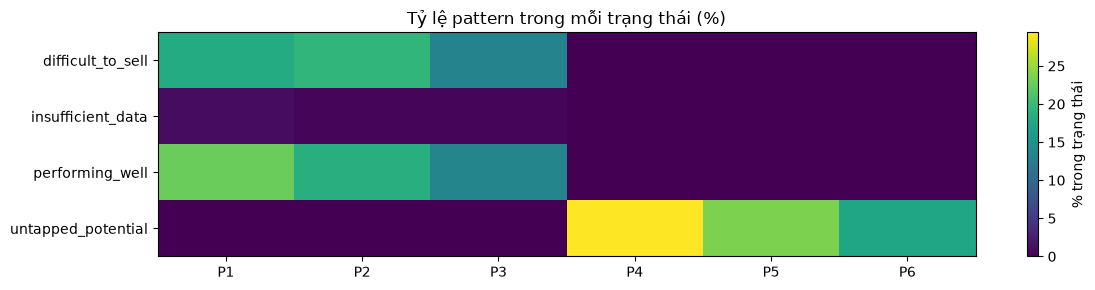

,status,pattern_exact,n_products,status_n,pct_within_status
15,difficult_to_sell,review_price_positioning,2395,12380,19.35
1,difficult_to_sell,add_product_images,2244,12380,18.13
8,difficult_to_sell,add_product_images + review_price_positioning,1635,12380,13.21
13,difficult_to_sell,improve_product_description,401,12380,3.24
6,difficult_to_sell,add_product_images + improve_product_description,380,12380,3.07
17,insufficient_data,add_product_images,52,5128,1.01
21,insufficient_data,add_product_images + review_price_positioning,23,5128,0.45
25,insufficient_data,review_price_positioning,19,5128,0.37
22,insufficient_data,consider_product_video,13,5128,0.25
18,insufficient_data,add_product_images + consider_product_video,8,5128,0.16


In [7]:
status_n=products.groupby('status').size().rename('status_n').reset_index()
status_pat=(products.groupby(['status','pattern_exact']).size().rename('n_products').reset_index()
            .merge(status_n,on='status'))
status_pat['pct_within_status']=(100*status_pat.n_products/status_pat.status_n).round(2)
status_pat.to_csv(OUTPUT/'rq3_pattern_by_status.csv',index=False)
status_top=status_pat[status_pat.pattern_exact.isin(selected)]
heat_s=(status_top.pivot(index='status',columns='pattern_exact',values='pct_within_status')
        .fillna(0).reindex(columns=selected,fill_value=0))
fig,ax=plt.subplots(figsize=(12,max(3,0.65*len(heat_s))))
im=ax.imshow(heat_s.to_numpy(),aspect='auto')
ax.set_yticks(range(len(heat_s)),heat_s.index)
ax.set_xticks(range(len(heat_s.columns)),[f'P{i+1}' for i in range(len(heat_s.columns))])
ax.set_title('Tỷ lệ pattern trong mỗi trạng thái (%)')
fig.colorbar(im,ax=ax,label='% trong trạng thái');fig.tight_layout()
fig.savefig(OUTPUT/'rq3_status_pattern_heatmap.png',dpi=160);plt.show()
display(status_pat[status_pat.pattern_exact!='No recommendation'].sort_values(['status','n_products'],ascending=[True,False]).groupby('status').head(5))

## RQ4 — Độ phức tạp hành động

Một sản phẩm có 0, 1 hoặc nhiều hạng mục rà soát. Số lượng đề xuất không phải thứ tự ưu tiên hay bằng chứng mức độ nghiêm trọng.

,n_products
n_actions,
0,13880
1,15612
2,9441
3,2421
4,215
5,7


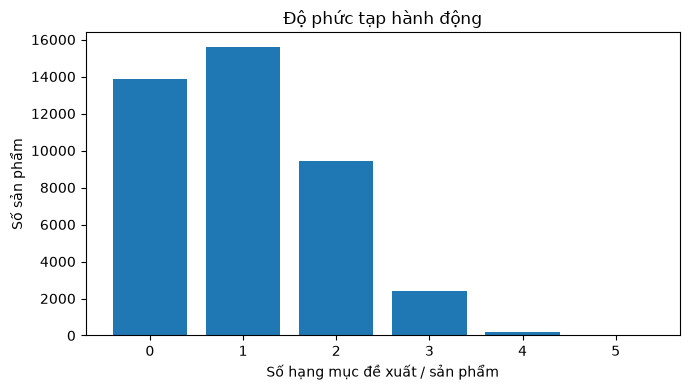

In [8]:
complexity=products.groupby(['status','n_actions']).size().rename('n_products').reset_index()
complexity=complexity.merge(status_n,on='status')
complexity['pct_within_status']=(100*complexity.n_products/complexity.status_n).round(2)
complexity.to_csv(OUTPUT/'rq4_action_complexity_by_status.csv',index=False)
display(products.n_actions.value_counts().sort_index().rename_axis('n_actions').to_frame('n_products'))
fig,ax=plt.subplots(figsize=(7,4))
vv=products.n_actions.value_counts().sort_index()
ax.bar(vv.index.astype(str),vv.values)
ax.set(xlabel='Số hạng mục đề xuất / sản phẩm',ylabel='Số sản phẩm',title='Độ phức tạp hành động')
fig.tight_layout();fig.savefig(OUTPUT/'rq4_action_complexity.png',dpi=160);plt.show()

## 5. Case study phục vụ web prototype

Xuất sản phẩm đại diện của những pattern thường gặp. Đây là mẫu **có chủ đích để minh họa UI**, không dùng làm ước lượng độ chính xác hoặc tần suất mẫu hình. Evidence, hypothesis và validation vẫn giữ nguyên từ NL.

In [9]:
top_for_cases=frequency[frequency.pattern_exact!='No recommendation'].head(6).pattern_exact.tolist()
case_rows=[]
for pattern in top_for_cases:
    part=products[products.pattern_exact==pattern].sort_values(['opportunity_score','product_id'],ascending=[False,True],na_position='last').head(5)
    case_rows.append(part)
cases=pd.concat(case_rows,ignore_index=True) if case_rows else products.iloc[0:0].copy()
case_ids=set(cases.product_id)
case_recs=recs[recs.product_id.isin(case_ids)].copy()
cases[['product_id','product_name','product_type','status','opportunity_score','n_actions','pattern_exact']].to_csv(OUTPUT/'case_study_products.csv',index=False)
case_recs.to_csv(OUTPUT/'case_study_recommendations.csv',index=False)
display(cases[['product_id','product_name','product_type','status','pattern_exact']].head(15))

,product_id,product_name,product_type,status,pattern_exact
0,102130535,Băng đô cài tóc đính ngọc trai nhỏ phong cách ...,trang sức,performing_well,add_product_images
1,204211694,"Ba Lô Nam Nữ Cao Cấp Đi Làm Đi Học, Du Lịch, P...",balo,performing_well,add_product_images
2,162549110,"Balo Nam, Balo Đi Học, Đi Chơi Cá Tính | Balo ...",balo,performing_well,add_product_images
3,46235521,Kính râm Mắt vuông thời trang cho Nam và Nữ,kính mắt,performing_well,add_product_images
4,164075062,Balo thời trang đi học đi làm đựng laptop BKN0...,balo,performing_well,add_product_images
5,215911695,"Chai xịt tạo bọt nano vệ sinh ô tô, giày dép, ...",phụ kiện vệ sinh giày,performing_well,review_price_positioning
6,209892587,Lót giày cao gót đa năng chuyên dùng khi mang ...,phụ kiện vệ sinh giày,performing_well,review_price_positioning
7,249470755,"Balo nam cao cấp công sở GUBAG đựng laptop 13,...",balo,performing_well,review_price_positioning
8,207809834,Ví Nam Nhỏ Gọn Dáng Đứng Đẹp Chất Liệu Vải Can...,ví nam,performing_well,review_price_positioning
9,217143527,Set 3 dụng cụ uốn tóc tạo kiểu gợn sóng tiện d...,phụ kiện tóc,performing_well,review_price_positioning


## 6. Tự động viết bản nháp insight và gợi ý tính năng

Bản nháp chỉ mô tả các bảng đã tính. **Không suy luận** rằng pattern là nguyên nhân bán thấp, không tự tạo thứ tự hành động. Đọc lại kết quả và chọn 1–2 điểm đáng kể để trình bày.

In [10]:
top3=frequency[frequency.pattern_exact!='No recommendation'].head(3)
lines=['# Improvement Pattern Discovery — Bản nháp kết quả','',
       f'- Dataset: **{total:,}** sản phẩm; **{n_with:,}** sản phẩm có ít nhất một recommendation; **{len(recs):,}** dòng recommendation.',
       f'- Có **{len(frequency)-int((frequency.pattern_exact=="No recommendation").any())}** tổ hợp recommendation khác nhau.',
       '', '## Top 3 tổ hợp', '']
for _,r in top3.iterrows():
    lines.append(f'- `{r.pattern_exact}`: **{int(r.n_products):,}** sản phẩm (**{r.pct_all:.2f}%** toàn bộ, **{r.pct_with_recs:.2f}%** sản phẩm có recommendation).')
lines += ['', '## Giá trị đề xuất cho web',
          '- **Pattern Summary:** Hiển thị tổ hợp các hạng mục cần rà soát của sản phẩm, liên kết với evidence và bước xác minh hiện có.',
          '- **Category Pattern Explorer:** Cho phép xem tần suất các pattern theo product_type, chỉ hiển thị nhóm đủ số mẫu và có mẫu số.',
          '- **Không tự động ưu tiên thứ tự hành động** từ tần suất pattern; thứ tự cần có tiêu chí sản phẩm độc lập.',
          '', '## Giới hạn',
          '- Pattern được khai thác từ các recommendation do pipeline rule-based sinh ra, không phải kiểm chứng độc lập về chất lượng listing.',
          '- Dữ liệu snapshot; không suy ra tác động nhân quả hoặc sự gia tăng doanh số sau khi chỉnh sửa.',
          '- So sánh theo product_type phụ thuộc taxonomy hiện hành; kết quả cần trình bày như phân tích thử nghiệm.',
          '', '## File liên quan',
          '- rq1_exact_pattern_frequency.csv, rq1_rule_cooccurrence.csv',
          '- rq2_pattern_by_product_type.csv, rq3_pattern_by_status.csv',
          '- rq4_action_complexity_by_status.csv, case_study_products.csv, case_study_recommendations.csv']
report='\n'.join(lines)
(OUTPUT/'improvement_pattern_report_draft.md').write_text(report,encoding='utf-8')
display(Markdown(report))
print('Đã xuất:',len(list(OUTPUT.iterdir())),'files tại',OUTPUT)

# Improvement Pattern Discovery — Bản nháp kết quả

- Dataset: **41,576** sản phẩm; **27,696** sản phẩm có ít nhất một recommendation; **42,652** dòng recommendation.
- Có **41** tổ hợp recommendation khác nhau.

## Top 3 tổ hợp

- `add_product_images`: **6,416** sản phẩm (**15.43%** toàn bộ, **23.17%** sản phẩm có recommendation).
- `review_price_positioning`: **5,774** sản phẩm (**13.89%** toàn bộ, **20.85%** sản phẩm có recommendation).
- `add_product_images + review_price_positioning`: **4,092** sản phẩm (**9.84%** toàn bộ, **14.77%** sản phẩm có recommendation).

## Giá trị đề xuất cho web
- **Pattern Summary:** Hiển thị tổ hợp các hạng mục cần rà soát của sản phẩm, liên kết với evidence và bước xác minh hiện có.
- **Category Pattern Explorer:** Cho phép xem tần suất các pattern theo product_type, chỉ hiển thị nhóm đủ số mẫu và có mẫu số.
- **Không tự động ưu tiên thứ tự hành động** từ tần suất pattern; thứ tự cần có tiêu chí sản phẩm độc lập.

## Giới hạn
- Pattern được khai thác từ các recommendation do pipeline rule-based sinh ra, không phải kiểm chứng độc lập về chất lượng listing.
- Dữ liệu snapshot; không suy ra tác động nhân quả hoặc sự gia tăng doanh số sau khi chỉnh sửa.
- So sánh theo product_type phụ thuộc taxonomy hiện hành; kết quả cần trình bày như phân tích thử nghiệm.

## File liên quan
- rq1_exact_pattern_frequency.csv, rq1_rule_cooccurrence.csv
- rq2_pattern_by_product_type.csv, rq3_pattern_by_status.csv
- rq4_action_complexity_by_status.csv, case_study_products.csv, case_study_recommendations.csv

Đã xuất: 12 files tại /Users/nhung/Documents/j4f-commerce-intelligence/data/processed/improvement_pattern_outputs


## 7. Checklist chọn insight để trình bày

- [ ] Pattern được nêu có **số lượng và tỷ lệ** rõ ràng, mẫu số phù hợp.
- [ ] Phân biệt **pattern phổ biến** với **pattern đặc trưng của một loại hàng** (tính tỷ lệ theo product_type, không chỉ đếm tổng).
- [ ] Chứng minh giá trị UX **ngoài việc lặp lại danh sách recommendation**: tóm tắt nhiều hành động, hỗ trợ lọc nhóm, dẫn đến bằng chứng.
- [ ] Giữ evidence và validation của NL; **không** tự khẳng định nguyên nhân hay hiệu quả cải thiện sales.
- [ ] Chọn vài case thực tế để đưa vào prototype, không dùng case mẫu có chủ đích để ước lượng độ phổ biến.

**Gợi ý giao diện:** `Product Detail → Improvement Pattern (tag) → Các hạng mục → Evidence & Validation`, và dashboard `Patterns by product_type`.